### My First Kalman-Filter implementatio

Eine erste einfache Implemetierung des Kalman-Filters

In [2]:
# Bibs
import numpy as np
import matplotlib.pyplot as plt

# Definition des zu simulierenden Systems

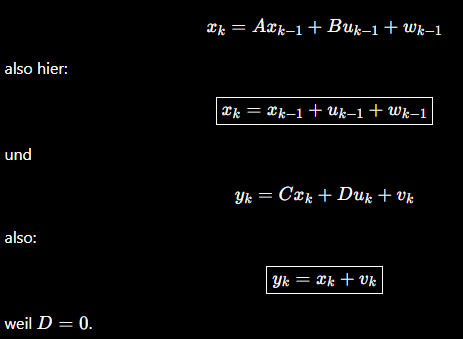

In [3]:
# Define the system parameters
SigmaW = 1.0 # Process noise covariance
SigmaV = 1.0 # Measurement noise covariance

A = 1.0 # State transition matrix
B = 1.0 # Control input matrix
C = 1.0 # Measurement matrix
D = 0.0 # Direct transmission matrix

max_iter = 40 # Number of iterations

In [13]:
# Generate random numbers
rng = np.random.default_rng(10) # Make a random number generator with a fixed seed for reproducibility

# initial values 

x_true = 0.0 # real state
x_hat = 0.0 # estimated state
SigmaX = 0.0 # error covariance of the state estimate
u = 0.0 # control input

# Storage allocation

x_store = np.zeros(max_iter + 1) # storage for true state + initial state
x_hat_store = np.zeros(max_iter) # storage for estimated state
SigmaX_store = np.zeros(max_iter) # storage for error covariance of the state estimate

x_store[0] = x_true # store initial true state

## Hier kommt der Kalman-Filter

Es werden die bereits besprochenen Schritte 1a..c uns 2a..c

In [14]:
# Inside the loop, one Kalman Filter iteration is performed

for k in range(max_iter):
    # Step 1a: State prediction
    x_hat = A * x_hat + B * u
    # Step 1b: Error covariance prediction
    SigmaX = A * SigmaX * A + SigmaW # Since everything is scalar, the transpose of A is just A itself

    # ------------------------------------------------
    # Simulate the real system
    # ------------------------------------------------

    # Simulation of an actual input signal
    u = 0.5 * rng.standard_normal() + np.cos((k + 1) / np.pi)
    # Simulation of process noise
    w = np.sqrt(SigmaW) * rng.standard_normal()
    # Simulation of measurement noise
    v = np.sqrt(SigmaV) * rng.standard_normal()

    # Generate a measurement based on the true state and the measurement noise
    z_true = C * x_true + D * u + v # Remember that D is 0, so the term D * u will be 0, C is 1, so z_true = x_true + v
    # The sensor measures the true state with some noise
    x_true = A * x_true + B * u + w # Simulation of the true state evolution with process noise


    # ------------------------------------------------
    # Kalman correction
    # ------------------------------------------------

    # Step 1c: Prediction of the measurement
    z_hat = C * x_hat + D * u # Since D is 0, this simplifies to z_hat = C * x_hat

    # Step 2a: Compute the Kalman gain
    L = SigmaX * C / (C * SigmaX * C + SigmaV) # Since everything is scalar, the transpose of C is just C itself

    # Kalculate the innovation (the difference between the actual measurement and the predicted measurement)
    innovation = z_true - z_hat

    # Step 2b: State correction
    x_hat = x_hat + L * innovation

    # Step 2c: Error covariance correction
    SigmaX = (1 - L * C) * SigmaX # Since everything is scalar

    # Store the data from this iteration
    x_store[k + 1] = x_true
    x_hat_store[k] = x_hat
    SigmaX_store[k] = SigmaX

# Visualizing the Calculations

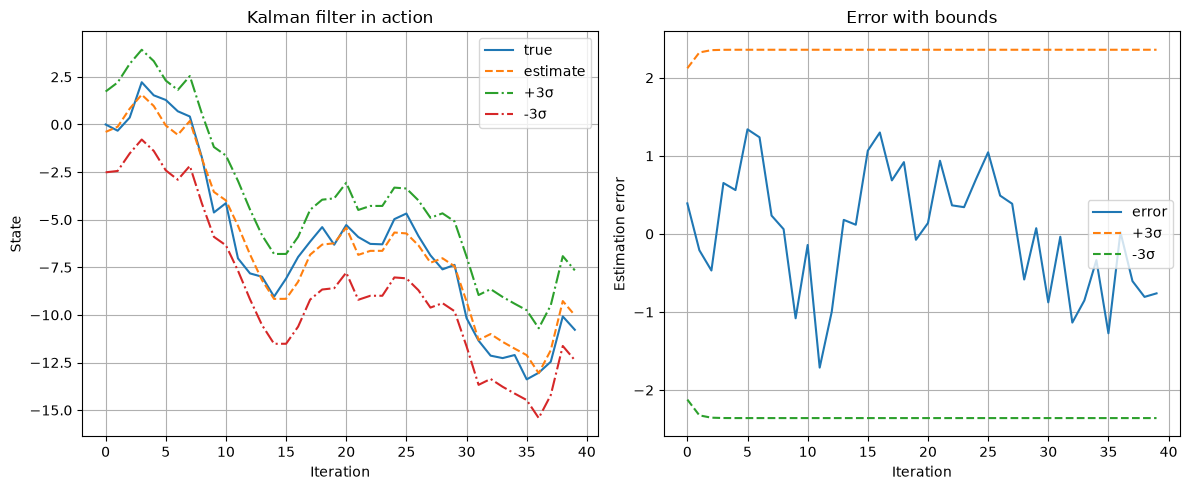

In [15]:
iterations = np.arange(max_iter)

bounds = 3 * np.sqrt(SigmaX_store)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# State estimate
axes[0].plot(iterations, x_store[:max_iter], label="true")
axes[0].plot(iterations, x_hat_store, "--", label="estimate")
axes[0].plot(iterations, x_hat_store + bounds, "-.", label="+3σ")
axes[0].plot(iterations, x_hat_store - bounds, "-.", label="-3σ")

axes[0].grid()
axes[0].legend()
axes[0].set_title("Kalman filter in action")
axes[0].set_xlabel("Iteration")
axes[0].set_ylabel("State")

# Estimation error
est_err = x_store[:max_iter] - x_hat_store

axes[1].plot(iterations, est_err, label="error")
axes[1].plot(iterations, bounds, "--", label="+3σ")
axes[1].plot(iterations, -bounds, "--", label="-3σ")

axes[1].grid()
axes[1].legend()
axes[1].set_title("Error with bounds")
axes[1].set_xlabel("Iteration")
axes[1].set_ylabel("Estimation error")

plt.tight_layout()
plt.show()